# Experiment 1: Linear Regression with One Variable
### Objective:
Implement linear regression with one variable on the California Housing dataset to predict housing prices based on a single feature (`AveRooms` — the average number of rooms per dwelling).

### Tasks Covered:
1. Load and preprocess the dataset.
2. Implement linear regression using both **Gradient Descent (from scratch)** and the **Normal Equation**.
3. Evaluate the model performance using metrics such as Mean Squared Error (**MSE**) and **R-squared ($R^2$)**.
4. Visualize the fitted line along with the data points.

---
## Step 1: Data Ingestion & Preprocessing
We load the California Housing dataset using `sklearn.datasets`, extract our target feature array, and handle scale normalization using `StandardScaler` to help gradient descent converge efficiently.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# -----------------------------
# Load the Dataset
# -----------------------------
california = fetch_california_housing(as_frame=True)
df = california.frame

# Feature (AveRooms) and Target (MedHouseVal)
X = df[['AveRooms']].values
y = df['MedHouseVal'].values.reshape(-1, 1)

print("Dataset Loaded Successfully")
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

# -----------------------------
# Split into Training and Testing Sets
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% testing
    random_state=42
)

print("\nTraining Set")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting Set")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# -----------------------------
# Standard Scaling
# -----------------------------
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# -----------------------------
# Add Bias Term
# -----------------------------
X_train_b = np.c_[np.ones((len(X_train_scaled), 1)), X_train_scaled]
X_test_b = np.c_[np.ones((len(X_test_scaled), 1)), X_test_scaled]

# -----------------------------
# Normal Equation (Training)
# -----------------------------
theta_normal = np.linalg.inv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train_scaled

# Predictions on Test Set
y_pred_scaled = X_test_b @ theta_normal
y_pred = scaler_y.inverse_transform(y_pred_scaled)

# -----------------------------
# Evaluation
# -----------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nNormal Equation Results")
print("Theta:")
print(theta_normal)

print(f"\nMean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

Dataset Loaded Successfully
Feature Shape: (20640, 1)
Target Shape: (20640, 1)

Training Set
X_train: (16512, 1)
y_train: (16512, 1)

Testing Set
X_test: (4128, 1)
y_test: (4128, 1)

Normal Equation Results
Theta:
[[4.81385765e-17]
 [1.58484867e-01]]

Mean Squared Error: 1.2923
R² Score: 0.0138


---
## Step 2: Model Implementation
Here we define both strategies to calculate the parameters:
1. **Normal Equation Analytical Solution**: $\theta = (X^T X)^{-1} X^T y$
2. **Batch Gradient Descent from Scratch**: Iterative parameter optimizations based on cost updates.

In [7]:
# --- APPROACH A: Normal Equation ---
theta_normal_scaled = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_scaled)

# Generate and de-scale predictions for metrics evaluation
y_pred_normal_scaled = X_b.dot(theta_normal_scaled)
y_pred_normal = scaler_y.inverse_transform(y_pred_normal_scaled)


# --- APPROACH B: Batch Gradient Descent from Scratch ---
def compute_cost(X, y, theta):
    """Compute Mean Squared Error Cost."""
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return cost

def gradient_descent(X, y, theta, learning_rate, iterations):
    """Perform batch gradient descent to learn theta."""
    m = len(y)
    cost_history = []

    for i in range(iterations):
        gradients = (1 / m) * X.T.dot(X.dot(theta) - y)
        theta = theta - learning_rate * gradients
        cost_history.append(compute_cost(X, y, theta))

    return theta, cost_history

# Initialize hyperparameters
learning_rate = 0.01
iterations = 1500
initial_theta = np.zeros((2, 1))

# Run optimization loop
theta_gd_scaled, cost_history = gradient_descent(X_b, y_scaled, initial_theta, learning_rate, iterations)

# Generate and de-scale predictions
y_pred_gd_scaled = X_b.dot(theta_gd_scaled)
y_pred_gd = scaler_y.inverse_transform(y_pred_gd_scaled)

---
## Step 3: Performance Metric Evaluation
We unpack performance logs via Mean Squared Error (MSE) and $R^2$ scores across both calculated weights configurations to compare accuracy bounds.

In [8]:
mse_normal = mean_squared_error(y, y_pred_normal)
r2_normal = r2_score(y, y_pred_normal)

mse_gd = mean_squared_error(y, y_pred_gd)
r2_gd = r2_score(y, y_pred_gd)

print("----- MODEL EVALUATION RESULTS -----")
print(f"Normal Equation:\n  - Mean Squared Error (MSE): {mse_normal:.4f}\n  - R-squared (R²):           {r2_normal:.4f}")
print(f"Gradient Descent:\n  - Mean Squared Error (MSE): {mse_gd:.4f}\n  - R-squared (R²):           {r2_gd:.4f}\n")
print(f"Final Weights (Scaled) - Normal Equation: Intercept = {theta_normal_scaled[0][0]:.4f}, Slope = {theta_normal_scaled[1][0]:.4f}")
print(f"Final Weights (Scaled) - Gradient Descent: Intercept = {theta_gd_scaled[0][0]:.4f}, Slope = {theta_gd_scaled[1][0]:.4f}")

----- MODEL EVALUATION RESULTS -----
Normal Equation:
  - Mean Squared Error (MSE): 1.3008
  - R-squared (R²):           0.0231
Gradient Descent:
  - Mean Squared Error (MSE): 1.3008
  - R-squared (R²):           0.0231

Final Weights (Scaled) - Normal Equation: Intercept = 0.0000, Slope = 0.1519
Final Weights (Scaled) - Gradient Descent: Intercept = 0.0000, Slope = 0.1519


---
## Step 4: Visual Target Data Curves
We use `matplotlib` to render the fitted linear regression model curve plotted directly against actual data instances.

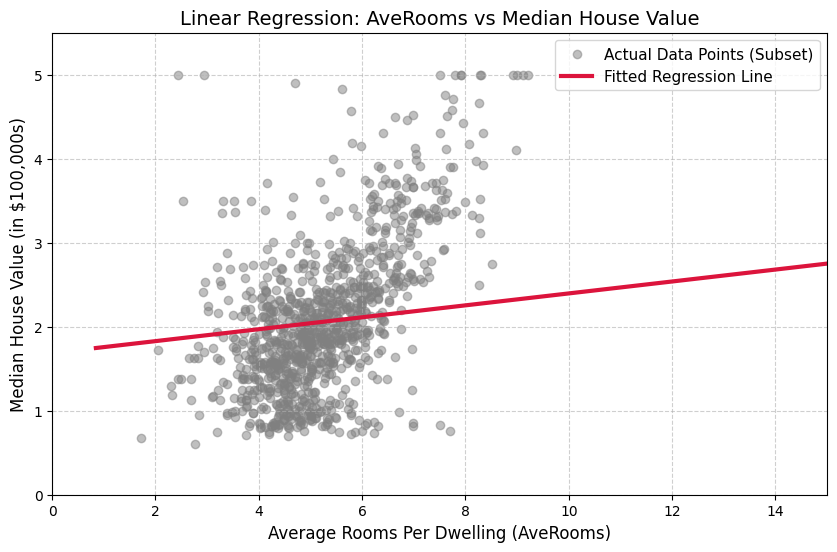

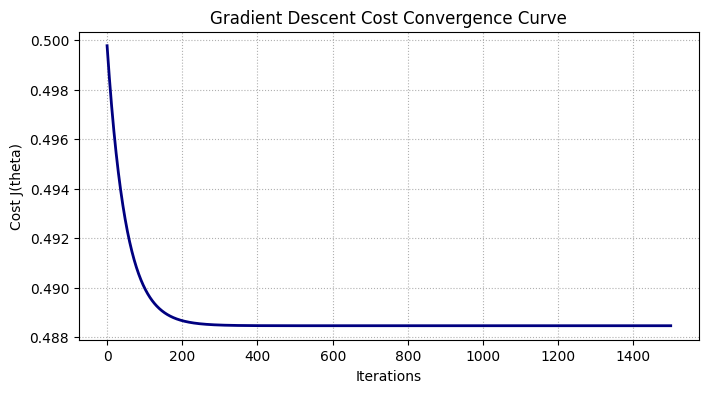

In [9]:
sort_axis = np.argsort(X.flatten())
X_sorted = X[sort_axis]
y_pred_gd_sorted = y_pred_gd[sort_axis]

plt.figure(figsize=(10, 6))
plt.scatter(X[:1000], y[:1000], color='gray', alpha=0.5, label='Actual Data Points (Subset)')
plt.plot(X_sorted, y_pred_gd_sorted, color='crimson', linewidth=3, label='Fitted Regression Line')

plt.title('Linear Regression: AveRooms vs Median House Value', fontsize=14)
plt.xlabel('Average Rooms Per Dwelling (AveRooms)', fontsize=12)
plt.ylabel('Median House Value (in $100,000s)', fontsize=12)
plt.xlim(0, 15)
plt.ylim(0, 5.5)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Plot Convergence curve history
plt.figure(figsize=(8, 4))
plt.plot(range(iterations), cost_history, color='navy', linewidth=2)
plt.title('Gradient Descent Cost Convergence Curve')
plt.xlabel('Iterations')
plt.ylabel('Cost J(theta)')
plt.grid(True, linestyle=':')
plt.show()